<a href="https://colab.research.google.com/github/APP155-Jarlego/APP155-JARLEGO/blob/main/JARLEGO%2C_Samantha_Lab_10_App_Phy_155.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[3.04593186 0.5189044 ]
[0.02927752 0.04896135]
Chi-Squared: 4.396672782174086
Degrees of Freedom: 4
1.0991681955435215
[3.04604328e+00 5.18383473e-01 5.48267391e-04]
Chi-Squared: 4.396658457815268
Degrees of Freedom: 3
1.465552819271756
[ 3.07673625  0.06287458  1.14106589 -0.77189579]
Chi-Squared: 2.273944126061582
Degrees of Freedom: 2
1.136972063030791


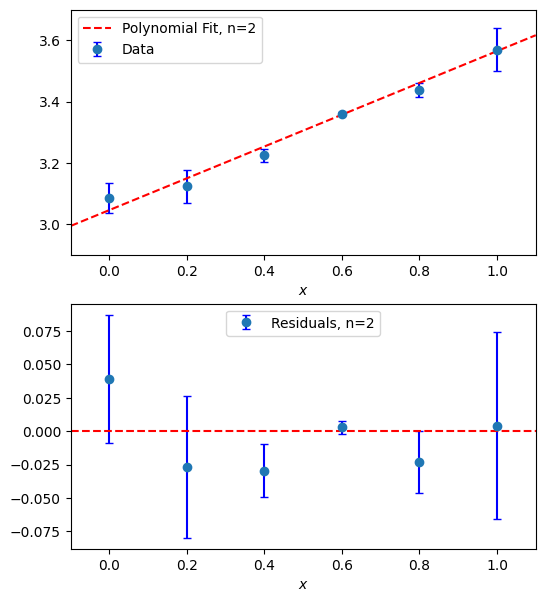

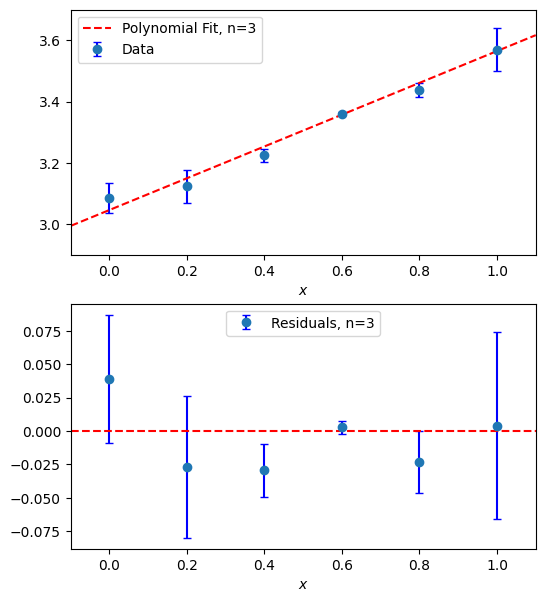

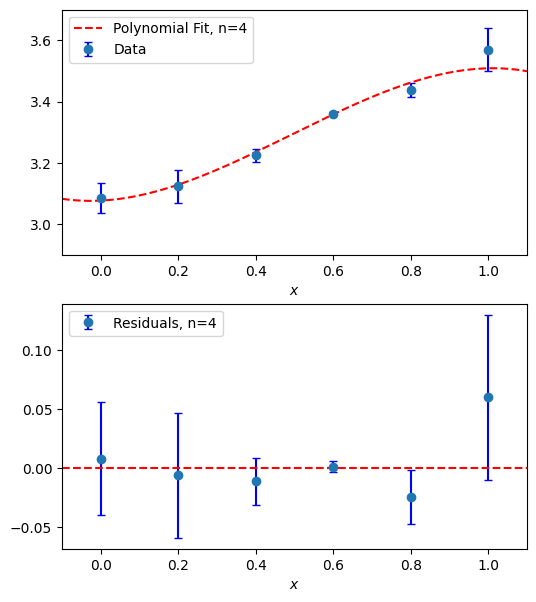

[100.29351591  -0.12795642  -1.84194305]
Chi-Squared: 0.01607066187912876
Degrees of Freedom: 4
0.00401766546978219
y0 = 100.29351590825337
v0 = -0.12795641642425928
g = 3.683886098913773
[138.23520811 -17.65208508]
Chi-Squared: 74.51077342604938
14.902154685209876


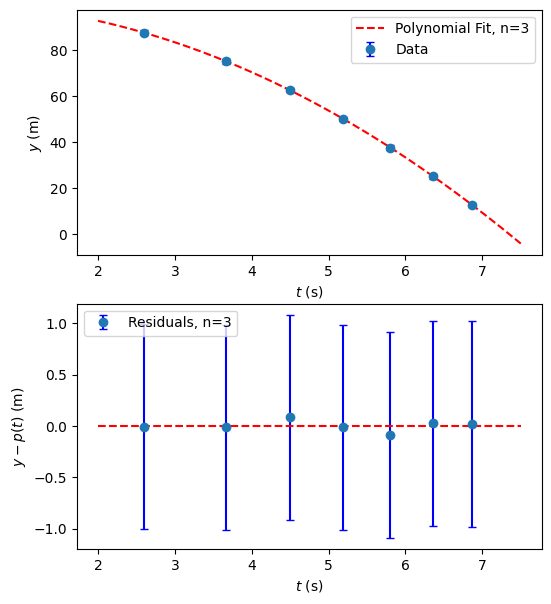

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def helpers(dataxs, datays, datasigs):
  S = np.sum(1/datasigs**2)
  Sx = np.sum(dataxs/datasigs**2)
  Sy = np.sum(datays/datasigs**2)
  Sxx = np.sum(dataxs**2/datasigs**2)
  Sxy = np.sum(dataxs*datays/datasigs**2)
  Del = S*Sxx - Sx**2
  return S, Sx, Sy, Sxx, Sxy, Del

def computecs(dataxs, datays, datasigs):
  S, Sx, Sy, Sxx, Sxy, Del = helpers(dataxs, datays, datasigs)
  cs = np.zeros(2);
  dcs = np.zeros(2);
  cs[0] = (Sxx*Sy - Sxy*Sx)/Del
  cs[1] = (S*Sxy - Sx*Sy)/Del
  dcs[0] = np.sqrt(Sxx/Del)
  dcs[1] = np.sqrt(S/Del)
  return cs, dcs

def computechisq(dataxs, datays, datasigs, cs):
  chisq = np.sum((datays-cs[0]-cs[1]*dataxs)**2/datasigs**2)
  return chisq

def morehelpers(dataxs, datays, datasigs):
  Sx3 = np.sum(dataxs**3/datasigs**2)
  Sx4 = np.sum(dataxs**4/datasigs**2)
  Sx5 = np.sum(dataxs**5/datasigs**2)
  Sx6 = np.sum(dataxs**6/datasigs**2)
  Sx2y = np.sum(dataxs**2*datays/datasigs**2)
  Sx3y = np.sum(dataxs**3*datays/datasigs**2)
  return Sx3, Sx4, Sx5, Sx6, Sx2y, Sx3y

def computecs3(dataxs, datays, datasigs):
  S, Sx, Sy, Sxx, Sxy, Del = helpers(dataxs, datays, datasigs)
  Sx3, Sx4, Sx5, Sx6, Sx2y, Sx3y = morehelpers(dataxs, datays, datasigs)
  A = np.array([[S, Sx, Sxx],
                [Sx, Sxx, Sx3],
                [Sxx, Sx3, Sx4]])
  B = np.array([Sy, Sxy, Sx2y])
  cs = np.linalg.solve(A, B)
  return cs

def computechisq3(dataxs, datays, datasigs, cs):
  chisq = np.sum((datays-cs[0]-cs[1]*dataxs-cs[2]*dataxs**2)**2/datasigs**2)
  return chisq

def computecs4(dataxs, datays, datasigs):
  S, Sx, Sy, Sxx, Sxy, Del = helpers(dataxs, datays, datasigs)
  Sx3, Sx4, Sx5, Sx6, Sx2y, Sx3y = morehelpers(dataxs, datays, datasigs)
  A = np.array([[S, Sx, Sxx, Sx3],
                [Sx, Sxx, Sx3, Sx4],
                [Sxx, Sx3, Sx4, Sx5],
                [Sx3, Sx4, Sx5, Sx6]])
  B = np.array([Sy, Sxy, Sx2y, Sx3y])
  cs = np.linalg.solve(A, B)
  return cs

def computechisq4(dataxs, datays, datasigs, cs):
  chisq = np.sum((datays-cs[0]-cs[1]*dataxs-cs[2]*dataxs**2-cs[3]*dataxs**3)**2/datasigs**2)
  return chisq

#Part 1
dataxs = np.linspace(0,1,6)
datays = np.array([3.085, 3.123, 3.224, 3.360, 3.438, 3.569])
datasigs = np.array([0.048, 0.053, 0.02, 0.005, 0.023, 0.07])

#n=2
cs2, dcs2 = computecs(dataxs, datays, datasigs)
print(cs2)
print(dcs2)

chisq2 = computechisq(dataxs, datays, datasigs, cs2)
print('Chi-Squared:', chisq2)
print('Degrees of Freedom:', dataxs.size - cs2.size)
print(chisq2/(dataxs.size - cs2.size))

#n=3
cs3 = computecs3(dataxs, datays, datasigs)
print(cs3)

chisq3 = computechisq3(dataxs, datays, datasigs, cs3)
print('Chi-Squared:', chisq3)
print('Degrees of Freedom:', dataxs.size - cs3.size)
print(chisq3/(dataxs.size - cs3.size))

#n=4
cs4 = computecs4(dataxs, datays, datasigs)
print(cs4)

chisq4 = computechisq4(dataxs, datays, datasigs, cs4)
print('Chi-Squared:', chisq4)
print('Degrees of Freedom:', dataxs.size - cs4.size)
print(chisq4/(dataxs.size - cs4.size))

#plotting fit and residuals for n=2
xs = np.linspace(-0.1, 1.1, 200)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7))

ax1.set_xlim(-0.1, 1.1)
ax1.set_ylim(2.9, 3.7)

ax1.errorbar(dataxs, datays, yerr=datasigs, fmt='o', ecolor='blue', capsize=3, label='Data')
ax1.plot(xs, cs2[0]+cs2[1]*xs, linestyle='--', color='red', label='Polynomial Fit, n=2')

ax1.legend()
ax1.set_xlabel(r'$x$')

residuals2 = datays - (cs2[0] + cs2[1]*dataxs)

ax2.set_xlim(-0.1, 1.1)

ax2.errorbar(dataxs, residuals2, yerr=datasigs, fmt='o', ecolor='blue', capsize=3, label='Residuals, n=2')
ax2.plot(xs, 0*xs, linestyle="--", color='red')

ax2.legend()
ax2.set_xlabel(r'$x$')

plt.show()

#plotting fit and residuals for n=3
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7))

ax1.set_xlim(-0.1, 1.1)
ax1.set_ylim(2.9, 3.7)

ax1.errorbar(dataxs, datays, yerr=datasigs, fmt='o', ecolor='blue', capsize=3, label='Data')
ax1.plot(xs, cs3[0]+cs3[1]*xs+cs3[2]*xs**2, linestyle='--', color='red', label='Polynomial Fit, n=3')

ax1.legend()
ax1.set_xlabel(r'$x$')

residuals3 = datays - (cs3[0] + cs3[1]*dataxs+cs3[2]*dataxs**2)

ax2.set_xlim(-0.1, 1.1)

ax2.errorbar(dataxs, residuals3, yerr=datasigs, fmt='o', ecolor='blue', capsize=3, label='Residuals, n=3')
ax2.plot(xs, 0*xs, linestyle="--", color='red')

ax2.legend()
ax2.set_xlabel(r'$x$')

plt.show()

#plotting fit and residuals for n=4
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7))

ax1.set_xlim(-0.1, 1.1)
ax1.set_ylim(2.9, 3.7)

ax1.errorbar(dataxs, datays, yerr=datasigs, fmt='o', ecolor='blue', capsize=3, label='Data')
ax1.plot(xs, cs4[0]+cs4[1]*xs+cs4[2]*xs**2+cs4[3]*xs**3, linestyle='--', color='red', label='Polynomial Fit, n=4')

ax1.legend()
ax1.set_xlabel(r'$x$')

residuals3 = datays - (cs4[0] + cs4[1]*dataxs+cs4[2]*dataxs**2+cs4[3]*dataxs**3)

ax2.set_xlim(-0.1, 1.1)

ax2.errorbar(dataxs, residuals3, yerr=datasigs, fmt='o', ecolor='blue', capsize=3, label='Residuals, n=4')
ax2.plot(xs, 0*xs, linestyle="--", color='red')

ax2.legend()
ax2.set_xlabel(r'$x$')

plt.show()



#Part 2
ffdatats = np.array([6.87, 6.36, 5.80, 5.19, 4.50, 3.67, 2.60])
ffdatays = np.array([12.5, 25.,37.5, 50., 62.5, 75., 87.5])
ffdatasigs = np.ones(ffdatats.size) #for uniform uncertainty of 1m

#fit w/ n=3
ffcs3 = computecs3(ffdatats, ffdatays, ffdatasigs)
print(ffcs3)

ffchisq3 = computechisq3(ffdatats, ffdatays, ffdatasigs, ffcs3)
print('Chi-Squared:', ffchisq3)
print('Degrees of Freedom:', ffdatats.size - ffcs3.size)
print(ffchisq3/(ffdatats.size - ffcs3.size))

g = -2*ffcs3[2]

print('y0 =', ffcs3[0])
print('v0 =', ffcs3[1])
print('g =', g)

#for comparison, a straight line fit(n=2) to the same data
ffcs2, ffdcs2 = computecs(ffdatats, ffdatays, ffdatasigs)
ffchisq2 = computechisq(ffdatats, ffdatays, ffdatasigs, ffcs2)
print(ffcs2)
print('Chi-Squared:', ffchisq2)
print(ffchisq2/(ffdatats.size - ffcs2.size))

#plotting fit and residuals
ts = np.linspace(2, 7.5, 200)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7))

ax1.errorbar(ffdatats, ffdatays, yerr=ffdatasigs, fmt='o', ecolor='blue', capsize=3, label='Data')
ax1.plot(ts, ffcs3[0]+ffcs3[1]*ts+ffcs3[2]*ts**2, linestyle='--', color='red', label='Polynomial Fit, n=3')

ax1.legend()
ax1.set_xlabel(r'$t$ (s)')
ax1.set_ylabel(r'$y$ (m)')

ffresiduals = ffdatays - (ffcs3[0] + ffcs3[1]*ffdatats+ffcs3[2]*ffdatats**2)

ax2.errorbar(ffdatats, ffresiduals, yerr=ffdatasigs, fmt='o', ecolor='blue', capsize=3, label='Residuals, n=3')
ax2.plot(ts, 0*ts, linestyle="--", color='red')

ax2.legend()
ax2.set_xlabel(r'$t$ (s)')
ax2.set_ylabel(r'$y - p(t)$ (m)')

plt.show()
